# Turtle Breakout 01 — the turtle breakout on crypto perpetuals

Pre-registration: `discussions/Turtle_Breakout/001_claude_tb01_preregistration.md`. Code: `src/data_engineering/modeling/turtle_breakout.py`.

Rules (Rallio's version): long when price trades above the 20-day high; exit at the higher of entry $-2\,\mathrm{ATR}_{20}$ (fixed) and the 10-day low (trailing); no pyramiding; size $=0.02\,\mathrm{HWM}/(2\,\mathrm{ATR})$. Trading day 17:00–17:00 New York. Binance USD-M perpetuals, 5-minute fills, taker 0.05% + 1 bp per side, funding included.

Questions (as in the reviewed video): does it beat **luck** (random entries, same exits and sizing) and does it beat **doing nothing** (buy-and-hold at the same leverage)?

Environment: `TB01_DATA_DIR` (default `BINANCE_UM_DIR\long`), `TB01_ASSETS`, `TB01_N_NULL`, `TB01_SYNTHETIC=1`.

In [1]:
import os, sys, json, time, subprocess, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb

SYNTHETIC = os.getenv('TB01_SYNTHETIC', '0') == '1'
ASSETS = [a.strip().upper() for a in os.getenv('TB01_ASSETS', ','.join(tb.ASSETS)).split(',') if a.strip()]
P = tb.Params(n_null=int(os.getenv('TB01_N_NULL', str(tb.Params().n_null))))
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb01-')) / '01'; P = tb.Params(n_null=60, n_twin=400, n_boot=300)
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '01'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_breakout.py'],
                     cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr[-200:]); assert chk.returncode == 0, 'tests failed'
print(json.dumps(tb.registration(P), indent=1, default=str))

..............
----------------------------------------------------------------------
Ran 14 tests in 1.920s

OK

{
 "period": "day",
 "side": "long",
 "entry_n": 20,
 "exit_n": 10,
 "atr_n": 20,
 "stop_atr": 2.0,
 "risk_frac": 0.02,
 "max_pos_lev": 3.0,
 "start_equity": 100000.0,
 "fee": 0.0005,
 "slip": 0.0001,
 "funding": true,
 "min_bar_share": 0.8,
 "n_twin": 2000,
 "n_null": 1000,
 "block_days": 21,
 "n_boot": 2000,
 "alpha": 0.05,
 "seed": 19831,
 "status": "PREREGISTERED_TB001",
 "version": "TB01-0.1.0",
 "assets": [
  "BTC",
  "ETH",
  "SOL",
  "XRP"
 ],
 "common_start": "2020-10-15 00:00:00+00:00",
 "half_split": "2023-07-01 00:00:00+00:00",
 "trading_day": "17:00-17:00 America/New_York",
 "atr": "Wilder RMA of true range",
 "leverage_cap": "position notional <= max_pos_lev x last marked equity; no entries at equity <= 0",
 "primary": "period=day, side=long, 4-asset portfolio, 2% HWM risk, fees+slippage+funding",
 "gates": {
  "G1": "N2 random-entry portfolios with CAGR >= re

## 1. Data: 5-minute perpetual bars and funding

In [2]:
T0 = time.time(); B5, FUND, cov = {}, {}, []
for k, a in enumerate(ASSETS):
    if SYNTHETIC:
        b = tb.synthetic_5m(2200, seed=40 + k, trend=0.0, start='2019-11-01'); f = tb.synthetic_funding(b, 0.0001)
    else:
        b = tb.bars_5m(pd.read_parquet(DATA / f'{a}USDT_um_1m.parquet', columns=['open_time', 'open', 'high', 'low', 'close']))
        fp = DATA / 'basis' / 'funding' / f'{a}USDT_funding.parquet'
        f = tb.funding_events(pd.read_parquet(fp)) if fp.exists() else None
    B5[a], FUND[a] = b, f
    gaps = int((b.index.to_series().diff() > pd.Timedelta(minutes=5)).sum())
    cov.append({'asset': a, 'first_bar': b.index[0], 'last_bar': b.index[-1], 'bars_5m': len(b), 'gaps': gaps,
                'funding_events': 0 if f is None else len(f),
                'funding_first': None if f is None or not len(f) else f.t.iloc[0],
                'mean_funding_8h_bp': None if f is None or not len(f) else 1e4 * f.rate.mean()})
    print(a, f'{time.time() - T0:.0f}s')
cov = pd.DataFrame(cov); display(cov)
assert all(cov.funding_events > 0), 'funding missing: run the funding download (see README)'

def build(p):
    return {a: tb.prepare_asset(a, B5[a], FUND[a], p) for a in ASSETS}
DATA_D = build(P)
END = min(b.index[-1] for b in B5.values())
print('primary window:', tb.COMMON_START.date(), '->', END)

BTC 2s
ETH 3s
SOL 4s
XRP 5s


,asset,first_bar,last_bar,bars_5m,gaps,funding_events,funding_first,mean_funding_8h_bp
0,BTC,2020-01-01 00:05:00+00:00,2026-10-24 00:00:00+00:00,716544,0,7395,2020-01-01 00:00:00+00:00,1.070421
1,ETH,2020-01-01 00:05:00+00:00,2026-10-24 00:00:00+00:00,716544,0,7395,2020-01-01 00:00:00+00:00,1.263627
2,SOL,2020-09-14 07:05:00+00:00,2026-10-24 00:00:00+00:00,641004,2,6700,2020-09-13 16:00:00.004000+00:00,0.019449
3,XRP,2020-01-06 08:25:00+00:00,2026-10-24 00:00:00+00:00,713564,2,7379,2020-01-06 08:00:00+00:00,1.331039


primary window: 2020-10-15 -> 2026-10-24 00:00:00+00:00


## 2. Primary run: daily, long only, 4-asset portfolio

In [3]:
E, T, ST = tb.simulate(DATA_D, P, start=tb.COMMON_START, end=END)
m = tb.metrics(E, T)
print(json.dumps(m, indent=1, default=float))
print('mean / max gross leverage:', round(ST['mean_gross_leverage'], 3), round(ST['max_gross_leverage'], 3))
print('entry rate per eligible day:', {k: round(v, 4) for k, v in ST['p_entry'].items()})
by_asset = T.groupby('asset').apply(lambda g: pd.Series({'trades': len(g), 'win_rate': (g.pnl > 0).mean(),
    'profit_factor': g.pnl[g.pnl > 0].sum() / -g.pnl[g.pnl <= 0].sum(), 'pnl': g.pnl.sum(), 'funding': g.funding.sum(),
    'fees': g.fees.sum(), 'avg_hold_days': g.hold_bars.mean() * 5 / 1440}), include_groups=False)
display(by_asset.round(3))

{
 "start": "2020-10-15",
 "end": "2026-10-24",
 "years": 6.023271731690623,
 "final_equity": 2863169.1561331195,
 "total_return": 27.631691561331195,
 "cagr": 0.745298491464911,
 "sharpe": 1.565860810872366,
 "max_dd": -0.3606574409394919,
 "trades": 180,
 "win_rate": 0.40555555555555556,
 "profit_factor": 2.4189196508723656,
 "avg_hold_days": 17.582349537037036,
 "fees": 67361.98656245299,
 "funding": 287767.8246281793
}
mean / max gross leverage: 0.412 2.236
entry rate per eligible day: {'BTC': 0.0375, 'ETH': 0.0325, 'SOL': 0.034, 'XRP': 0.0264}


,trades,win_rate,profit_factor,pnl,funding,fees,avg_hold_days
asset,,,,,,,
BTC,49.0,0.388,1.916,464579.997,84891.895,23180.574,18.198
ETH,44.0,0.455,1.738,401413.774,74179.033,16857.319,19.280
SOL,46.0,0.435,2.242,578861.870,57829.496,13956.871,17.822
XRP,41.0,0.341,4.065,1318313.514,70867.401,13367.223,14.757


## 3. Does it beat doing nothing? Buy-and-hold at the same mean leverage

In [4]:
LEV = ST['mean_gross_leverage']
BH = tb.buy_and_hold(DATA_D, P, tb.COMMON_START, END, LEV)
BH1 = tb.buy_and_hold(DATA_D, P, tb.COMMON_START, END, 1.0)
mbh = tb.metrics(BH); mbh1 = tb.metrics(BH1)
SD = tb.sharpe_diff(E, BH, P, seed=P.seed)
cmp = pd.DataFrame({'strategy': m, f'buy&hold x{LEV:.2f}': mbh, 'buy&hold x1': mbh1}).loc[['cagr', 'sharpe', 'max_dd', 'total_return', 'final_equity']]
display(cmp.astype(float).round(3)); print('Sharpe difference (strategy - B&H at same leverage):', {k: round(v, 3) for k, v in SD.items()})

,strategy,buy&hold x0.41,buy&hold x1
cagr,0.745,0.277,0.445
sharpe,1.566,0.766,0.351
max_dd,-0.361,-0.980,-1.025
total_return,27.632,3.352,8.169
final_equity,2863169.156,433614.277,909039.299


Sharpe difference (strategy - B&H at same leverage): {'sharpe_strategy': 1.566, 'sharpe_bh': 0.766, 'diff': 0.8, 'lo': 0.043, 'hi': 1.448}


## 4. Does it beat luck? N1 trade twins and N2 random-entry portfolios

In [5]:
TW = tb.trade_twins(DATA_D, T, P, seed=P.seed + 1)
display(TW.round(3))
t1 = time.time()
NULL = tb.random_portfolios(DATA_D, P, ST['p_entry'], tb.COMMON_START, END, seed=P.seed + 2)
print(f'N2: {len(NULL)} runs, {time.time() - t1:.0f}s')
DEC = tb.decide(m, NULL, SD, P)
print(json.dumps(DEC, indent=1, default=float)); print('VERDICT:', DEC['verdict'])

,asset,trades,real_sum_ret,null_median,null_q95,share_null_ge_real
0,BTC,49,1.751,0.957,2.608,0.212
1,ETH,44,2.874,1.362,3.733,0.140
2,SOL,46,8.459,2.965,8.783,0.055
3,XRP,41,5.933,0.906,4.027,0.012
4,ALL,180,19.017,6.557,13.679,0.004


N2: 1000 runs, 57s
{
 "version": "TB01-0.1.0",
 "status": "PREREGISTERED_TB001",
 "real_cagr": 0.745298491464911,
 "real_sharpe": 1.565860810872366,
 "real_max_dd": -0.3606574409394919,
 "null_cagr_median": 0.23945413279036876,
 "null_share_cagr_ge_real": 0.0,
 "sharpe_sharpe_strategy": 1.566216809697216,
 "sharpe_sharpe_bh": 0.7660041696324557,
 "sharpe_diff": 0.8002126400647603,
 "sharpe_lo": 0.04269289157944509,
 "sharpe_hi": 1.4480448819679614,
 "G1_beats_luck": "PASS",
 "G2_beats_buy_and_hold": "PASS",
 "verdict": "TREND_EDGE"
}
VERDICT: TREND_EDGE


## 5. Reported variants (no decision)

In [6]:
variants = {}
def run_variant(name, p, data=None, n_null=0):
    d = data or build(p)
    Ev, Tv, Sv = tb.simulate(d, p, start=tb.COMMON_START, end=END)
    mv = tb.metrics(Ev, Tv); mv['mean_gross_leverage'] = Sv['mean_gross_leverage']
    if n_null:
        Nv = tb.random_portfolios(d, p, Sv['p_entry'], tb.COMMON_START, END, n=n_null, seed=P.seed + 7)
        mv['null_cagr_median'] = float(Nv.cagr.median()); mv['null_share_cagr_ge_real'] = float((Nv.cagr >= mv['cagr']).mean())
    variants[name] = (Ev, Tv, mv); print(name, f"cagr {mv['cagr']:.3f} sharpe {mv['sharpe']:.2f} maxdd {mv['max_dd']:.3f} trades {mv.get('trades', 0)}")
variants['primary'] = (E, T, {**m, 'mean_gross_leverage': LEV, 'null_cagr_median': DEC['null_cagr_median'], 'null_share_cagr_ge_real': DEC['null_share_cagr_ge_real']})
run_variant('no_funding', tb.replace(P, funding=False), n_null=200)
run_variant('short_only', tb.replace(P, side='short'), n_null=200)
run_variant('long_short', tb.replace(P, side='both'), n_null=200)
run_variant('hourly_long', tb.replace(P, period='hour'), n_null=100)
single = {}
for a in ASSETS:                       # each asset alone, full own history
    pa = P; da = {a: DATA_D[a]}
    st_a = B5[a].index[0] + pd.Timedelta(days=30)
    Ea, Ta, Sa = tb.simulate(da, pa, start=st_a, end=END)
    ma = tb.metrics(Ea, Ta); ma['twin_share'] = float(tb.trade_twins(da, Ta, pa, seed=P.seed + 3).query('asset == @a').share_null_ge_real.iloc[0]) if len(Ta) else np.nan
    single[a] = ma
VT = pd.DataFrame({k: v[2] for k, v in variants.items()}).T
show = ['cagr', 'sharpe', 'max_dd', 'trades', 'win_rate', 'profit_factor', 'avg_hold_days', 'mean_gross_leverage', 'funding', 'fees', 'null_cagr_median', 'null_share_cagr_ge_real']
display(VT[[c for c in show if c in VT]].astype(float).round(3))
SA = pd.DataFrame(single).T
display(SA[['start', 'cagr', 'sharpe', 'max_dd', 'trades', 'win_rate', 'profit_factor', 'funding', 'twin_share']])

no_funding cagr 0.857 sharpe 1.74 maxdd -0.352 trades 180
short_only cagr -0.090 sharpe 0.15 maxdd -0.903 trades 191
long_short cagr 0.703 sharpe 1.34 maxdd -0.431 trades 358
hourly_long cagr -0.977 sharpe 0.45 maxdd -1.000 trades 4906


,cagr,sharpe,max_dd,trades,win_rate,profit_factor,avg_hold_days,mean_gross_leverage,funding,fees,null_cagr_median,null_share_cagr_ge_real
primary,0.745,1.566,-0.361,180.0,0.406,2.419,17.582,0.412,287767.825,67361.987,0.239,0.000
no_funding,0.857,1.743,-0.352,180.0,0.422,2.557,17.582,0.404,0.000,93349.104,0.288,0.000
short_only,-0.090,0.151,-0.903,191.0,0.335,0.811,15.215,0.474,-2221.675,5519.802,-0.039,0.875
long_short,0.703,1.336,-0.431,358.0,0.369,1.626,16.645,0.705,252244.359,112300.328,0.314,0.000
hourly_long,-0.977,0.448,-1.000,4906.0,0.320,0.998,0.620,3.238,2001453.578,5988445.572,-0.982,0.350


,start,cagr,sharpe,max_dd,trades,win_rate,profit_factor,funding,twin_share
BTC,2020-01-31,0.122619,0.995742,-0.208081,54,0.388889,2.424231,24315.464099,0.239
ETH,2020-01-31,0.111453,0.878828,-0.128422,50,0.48,2.326903,27836.371465,0.1605
SOL,2020-10-14,0.201514,1.193963,-0.219331,46,0.434783,3.299428,18953.996962,0.0545
XRP,2020-02-05,0.194317,0.940361,-0.17647,47,0.340426,3.785587,20115.085325,0.018


## 6. Years and halves

In [7]:
YR = pd.DataFrame({'strategy': tb.yearly(E), f'buy&hold x{LEV:.2f}': tb.yearly(BH)})
display((100 * YR).round(1))
halves = []
for lab, a, b in (('2020-10 -> 2023-06', tb.COMMON_START, tb.HALF_SPLIT), ('2023-07 -> end', tb.HALF_SPLIT, END)):
    for nm, S in (('strategy', E), ('buy&hold', BH)):
        mm = tb.metrics(S[(S.index >= a) & (S.index < b)])
        halves.append({'window': lab, 'series': nm, 'cagr': mm['cagr'], 'sharpe': mm['sharpe'], 'max_dd': mm['max_dd']})
HV = pd.DataFrame(halves); display(HV.round(3))

,strategy,buy&hold x0.41
2020,59.4,19.1
2021,123.6,624.7
2022,-20.4,-94.7
2023,213.9,991.6
2024,107.4,82.4
2025,17.5,-36.7
2026,32.0,-24.7


,window,series,cagr,sharpe,max_dd
0,2020-10 -> 2023-06,strategy,0.649,1.448,-0.359
1,2020-10 -> 2023-06,buy&hold,0.074,0.742,-0.980
2,2023-07 -> end,strategy,0.833,1.664,-0.361
3,2023-07 -> end,buy&hold,0.477,0.879,-0.839


## 7. Figures

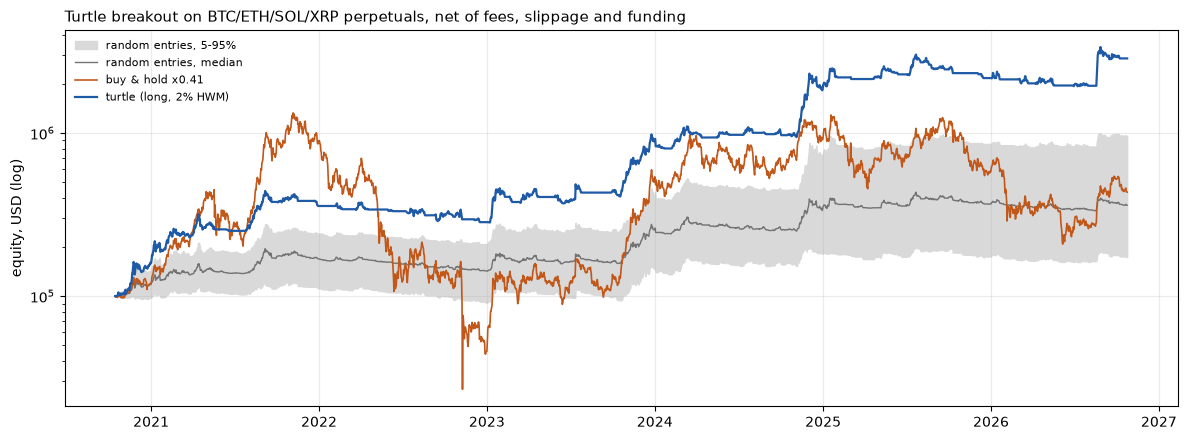

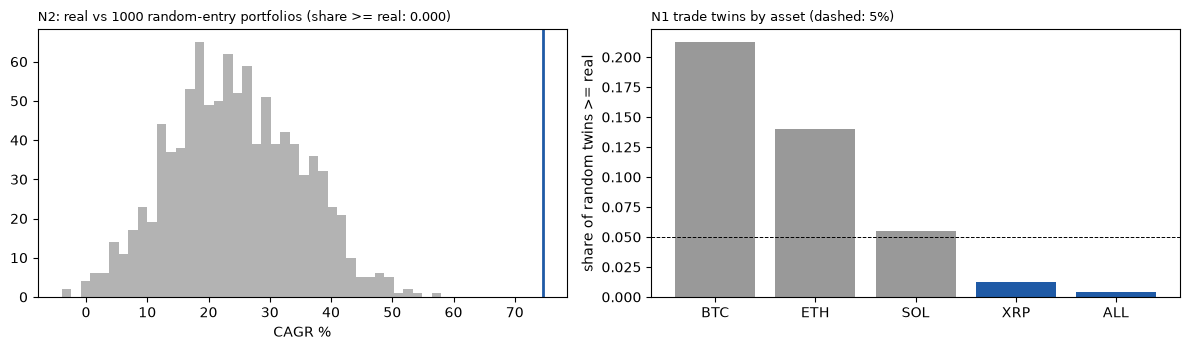

In [8]:
rng_paths = []
ss = np.random.SeedSequence(P.seed + 9)
for child in ss.spawn(200 if not SYNTHETIC else 30):
    En, _, _ = tb.simulate(DATA_D, P, tb.COMMON_START, END, mode='random', p_entry=ST['p_entry'], rng=np.random.default_rng(child), record=False)
    rng_paths.append(tb.daily(En))
RP = pd.concat(rng_paths, axis=1)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(RP.index, RP.quantile(0.05, axis=1), RP.quantile(0.95, axis=1), color='0.85', label='random entries, 5-95%')
ax.plot(RP.index, RP.median(axis=1), color='0.45', lw=1, label='random entries, median')
ax.plot(tb.daily(BH).index, tb.daily(BH), color='#c2571a', lw=1.2, label=f'buy & hold x{LEV:.2f}')
ax.plot(tb.daily(E).index, tb.daily(E), color='#1f5aa6', lw=1.6, label='turtle (long, 2% HWM)')
ax.set_yscale('log'); ax.set_ylabel('equity, USD (log)'); ax.grid(alpha=0.25); ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('Turtle breakout on BTC/ETH/SOL/XRP perpetuals, net of fees, slippage and funding', loc='left', fontsize=11)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(NULL.cagr * 100, bins=40, color='0.7'); axes[0].axvline(m['cagr'] * 100, color='#1f5aa6', lw=2)
axes[0].set_xlabel('CAGR %'); axes[0].set_title(f"N2: real vs {len(NULL)} random-entry portfolios (share >= real: {DEC['null_share_cagr_ge_real']:.3f})", fontsize=9, loc='left')
x = np.arange(len(TW)); axes[1].bar(x, TW.share_null_ge_real, color=['#1f5aa6' if s < 0.05 else '0.6' for s in TW.share_null_ge_real])
axes[1].axhline(0.05, color='k', lw=0.7, ls='--'); axes[1].set_xticks(x); axes[1].set_xticklabels(TW.asset)
axes[1].set_ylabel('share of random twins >= real'); axes[1].set_title('N1 trade twins by asset (dashed: 5%)', fontsize=9, loc='left')
plt.tight_layout(); plt.show()

## 8. Exports

In [9]:
eqs = {'primary': tb.daily(E), 'buy_hold_matched': tb.daily(BH), 'buy_hold_x1': tb.daily(BH1), 'random_median': RP.median(axis=1)}
eqs.update({k: tb.daily(v[0]) for k, v in variants.items() if k != 'primary'})
pd.DataFrame(eqs).to_csv(OUT / '01_equity_daily.csv', float_format='%.2f')
pd.concat([v[1].assign(variant=k) for k, v in variants.items()], ignore_index=True).to_csv(OUT / '01_trades.csv.gz', index=False, float_format='%.6g')
VT.to_csv(OUT / '01_variants.csv', float_format='%.6g'); SA.to_csv(OUT / '01_single_asset.csv', float_format='%.6g')
by_asset.to_csv(OUT / '01_by_asset.csv', float_format='%.6g'); TW.to_csv(OUT / '01_trade_twins.csv', index=False, float_format='%.6g')
NULL.to_csv(OUT / '01_null_portfolios.csv', index=False, float_format='%.6g'); YR.to_csv(OUT / '01_yearly.csv', float_format='%.6g')
HV.to_csv(OUT / '01_halves.csv', index=False, float_format='%.6g'); cmp.to_csv(OUT / '01_vs_buy_hold.csv', float_format='%.6g')
cov.to_csv(OUT / '01_coverage.csv', index=False)
(OUT / '01_decision.json').write_text(json.dumps({'decision': DEC, 'primary_metrics': m, 'leverage': {'mean': LEV, 'max': ST['max_gross_leverage']},
    'p_entry': ST['p_entry'], 'registration': tb.registration(P)}, indent=1, default=float))
(OUT / '01_manifest.json').write_text(json.dumps({'module': 'Turtle_Breakout_01', 'version': tb.VERSION, 'synthetic': SYNTHETIC,
    'assets': ASSETS, 'window': [str(tb.COMMON_START), str(END)], 'runtime_s': round(time.time() - T0, 1)}, indent=1))
print(sorted(p.name for p in OUT.iterdir()))

['01_by_asset.csv', '01_coverage.csv', '01_decision.json', '01_equity_daily.csv', '01_halves.csv', '01_manifest.json', '01_null_portfolios.csv', '01_single_asset.csv', '01_trade_twins.csv', '01_trades.csv.gz', '01_variants.csv', '01_vs_buy_hold.csv', '01_yearly.csv']
